# Module 02: LLM Prompt Engineering, Response Schemas & Operational Knowledge (DKP)

In Module 01, the deterministic Hanasaki rule ignored F.E. Walter's seasonal recreation/conservation schedule (`1,300 ↔ 1,370 ft`). In this module, we inspect how **HydroReOpLLM** constructs structured LLM operators and compare two experimental conditions side by side:

1. **Without operational knowledge** (`seasonal_target.yaml`) — `gemma4:12b` receives pool elevation, seasonal target, and 2-day release history.
2. **With operational knowledge** (`dkp.yaml`) — `gemma4:12b` dynamically retrieves prescriptive Water Control Manual rules from the **Decision Knowledge Package** (`dkp.md`) and cites `rules_applied` inside a strict JSON response schema.

| Stage | What You Do | Key HydroReOpLLM API / File |
| --- | --- | --- |
| **1. Configure** | Compare `seasonal_target.yaml` vs. `dkp.yaml` settings & dependency pins offline | `load_settings(..., runtime_root=REPO_ROOT)` |
| **2. Operate** | Inspect Day-1 prompt previews, `dkp.user.txt`, JSON schemas, and dynamic `dkp.md` rule retrieval | `report["prompt_previews"]`, `study/response_schemas.json`, `study/formatter.py` |
| **3. Execute** | Replay archived 2021 LLM decisions (`10` seeds × `2` conditions) + Rule-based offline (`0` calls) | `RecordedResponseBackend`, `run_network` |
| **4. Inspect & Plot** | Compute 2021 KGE/NSE/RMSE against USGS `01447780` & `01447800` and plot a 2-panel comparison | `study/observations.csv`, `study/archived_releases.csv` |


## 0. Locate the Repository & Configure Plotting

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt

def find_repo_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "examples" / "fe_walter" / "rule_based.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the HydroReOpLLM repository root. "
        "Launch JupyterLab from the repository root, tutorials/, or a module folder."
    )

REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "grid.linestyle": "--",
    "font.size": 9.5,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9.5,
    "legend.frameon": True,
    "legend.framealpha": 0.92,
    "legend.edgecolor": "#d8d8d8",
})

print("Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).")


Repository located cleanly (relative check: pyproject.toml + examples/fe_walter/rule_based.yaml found).


## 1. Configure — Compare `seasonal_target.yaml` vs. `dkp.yaml` Offline

Calling `load_settings` validates YAML keys, pins every prompt/schema/knowledge file by SHA-256, and renders an offline Day-1 prompt preview **without making any network call**.


In [2]:
import json
import pandas as pd
from llm_reservoir_agent.workflow import load_settings

fe_dir = REPO_ROOT / "examples" / "fe_walter"
st_settings = load_settings(fe_dir / "seasonal_target.yaml", runtime_root=REPO_ROOT)
dkp_settings = load_settings(fe_dir / "dkp.yaml", runtime_root=REPO_ROOT)

rows = []
for label, s in [
    ("Without knowledge (seasonal_target.yaml)", st_settings),
    ("With knowledge (dkp.yaml)", dkp_settings),
]:
    ag = s.agents["walter_operator"]
    raw_ag = s.data["agents"]["walter_operator"]
    mdl = ag["model"]
    deps = s.data.get("source_dependencies", {})
    rows.append({
        "Condition": label,
        "Method": raw_ag["study_method"],
        "Model": f"{mdl['provider']}/{mdl['model']}",
        "Temp / Seed": f"{mdl['temperature']} / {mdl['seed']}",
        "Deps Pinned": len(deps),
        "DKP Included": "dkp.md" in deps,
        "Planned Calls (7d)": s.report["planned_llm_calls"],
        "Check Net Calls": s.report["network_calls"],
    })

print("=== Experiment Configuration Comparison (Offline load_settings) ===")
print(pd.DataFrame(rows).to_string(index=False))


=== Experiment Configuration Comparison (Offline load_settings) ===
                               Condition          Method             Model Temp / Seed  Deps Pinned  DKP Included  Planned Calls (7d)  Check Net Calls
Without knowledge (seasonal_target.yaml) seasonal_target ollama/gemma4:12b     0.7 / 3            4         False                   7                0
               With knowledge (dkp.yaml)             dkp ollama/gemma4:12b     0.7 / 3            5          True                   7                0


## 2. Operate — Inspect Day-1 Prompt Previews, JSON Schemas & `dkp.md` Rule Retrieval

Notice how the **JSON response schema** (`study/response_schemas.json`) enforces a structured decision chain: the LLM must state `applicable_target_ft`, `pool_position`, `intended_storage_direction`, and `release_relation_to_inflow` *before* choosing `release_cfs`. The `dkp` condition further requires `operating_mode` and `rules_applied` citing exact sections retrieved from `dkp.md`.


In [3]:
import importlib.util

# 2a. Compare Day-1 prompt previews from load_settings
st_preview = st_settings.report["prompt_previews"]["walter_operator"]
dkp_preview = dkp_settings.report["prompt_previews"]["walter_operator"]

print("=== Offline Day-1 Prompt Preview Sizes (load_settings + prompts/*.user.txt) ===")
for name, prev, usr_file in [
    ("seasonal_target", st_preview, fe_dir / "prompts" / "seasonal_target.user.txt"),
    ("dkp", dkp_preview, fe_dir / "prompts" / "dkp.user.txt"),
]:
    sys_msg = next(m["content"] for m in prev["messages"] if m["role"] == "system")
    usr_msg = usr_file.read_text(encoding="utf-8")
    print(f"  {name:16s} | kind={prev['kind']} | model_used={prev['model_used']} | "
          f"system={len(sys_msg):,} chars | day1_user={len(usr_msg):,} chars")

# 2b. Compare JSON response schemas
schemas = json.loads((fe_dir / "study" / "response_schemas.json").read_text(encoding="utf-8"))
st_req = schemas["seasonal_target"]["required"]
dkp_req = schemas["dkp"]["required"]
print("\n=== Structured Output Schema Comparison (study/response_schemas.json) ===")
print(f"  seasonal_target required ({len(st_req)}): {st_req}")
print(f"  dkp required             ({len(dkp_req)}): {dkp_req}")
print(f"  Extra DKP audit fields       : {[f for f in dkp_req if f not in st_req]}")
print(f"  DKP operating_mode enum      : {schemas['dkp']['properties']['operating_mode']['enum']}")

# 2c. Preview Day-1 DKP user prompt (prompts/dkp.user.txt)
dkp_user_sample = (fe_dir / "prompts" / "dkp.user.txt").read_text(encoding="utf-8").splitlines()
print("\n=== Excerpt of examples/fe_walter/prompts/dkp.user.txt (First 18 lines) ===")
print("\n".join(dkp_user_sample[:18]))

# 2d. Demonstrate dynamic DKP rule retrieval across 3 contrasting operating regimes
spec = importlib.util.spec_from_file_location("fe_walter_formatter", fe_dir / "study" / "formatter.py")
formatter_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(formatter_mod)

prompt_builder = formatter_mod.StudyPrompt(
    fe_dir / "study" / "elevation_storage.csv",
    fe_dir / "dkp.md",
)

scenarios = [
    ("Winter above target (Jan 1)", "2021-01-01T00:00:00", 3_516.0, 10.67),
    ("Summer normal pool (Jun 15)", "2021-06-15T00:00:00", 18_215.0, 9.50),
    ("Summer flood storage (Aug 15)", "2021-08-15T00:00:00", 30_578.0, 65.00),
]

print("\n=== Dynamic DKP Rule Retrieval Across Regimes (dkp.md) ===")
for title, ts, storage_af, inflow_cms in scenarios:
    obs = {
        "timestamp": ts,
        "inflow_cms": inflow_cms,
        "state": {"storage_m3": storage_af * formatter_mod.PROMPT_ACRE_FOOT_M3},
    }
    rendered = prompt_builder.render(obs, history=())
    excerpts = [
        line.split(": ", 1)[1].split(" (")[0]
        for line in rendered.splitlines()
        if line.startswith("--- DKP excerpt ")
    ]
    elev = prompt_builder.pool_elevation_ft(storage_af)
    print(f"  {title:32s} | pool={elev:7.2f} ft | retrieved={excerpts}")


=== Offline Day-1 Prompt Preview Sizes (load_settings + prompts/*.user.txt) ===
  seasonal_target  | kind=config_preview | model_used=False | system=2,913 chars | day1_user=473 chars
  dkp              | kind=config_preview | model_used=False | system=5,454 chars | day1_user=6,744 chars

=== Structured Output Schema Comparison (study/response_schemas.json) ===
  seasonal_target required (6): ['applicable_target_ft', 'pool_position', 'intended_storage_direction', 'release_relation_to_inflow', 'reasoning', 'release_cfs']
  dkp required             (8): ['applicable_target_ft', 'pool_position', 'intended_storage_direction', 'release_relation_to_inflow', 'operating_mode', 'rules_applied', 'reasoning', 'release_cfs']
  Extra DKP audit fields       : ['operating_mode', 'rules_applied']
  DKP operating_mode enum      : ['pass_inflow', 'store_toward_target', 'draw_toward_target', 'minimum_release', 'flood_control', 'post_flood_drawdown', 'recreation_plan']

=== Excerpt of examples/fe_walter/pr

## 3. Execute — Offline 2021 Replay via `RecordedResponseBackend` (`0` Network Calls)

To inspect full-year LLM performance reproducibly with zero GPU or API cost, HydroReOpLLM ships `RecordedResponseBackend`. Below we replay all **10 seeds** of `without_knowledge` (`seasonal_target`) and **10 seeds** of `with_knowledge` (`dkp`) from `study/archived_releases.csv` alongside the 2021 Hanasaki rule baseline through `run_network` — verifying `0` network calls — and score every run against USGS `01447780` (reservoir pool level), `01447800` (release), and `01449000` (Lehighton downstream flow).


In [4]:
import csv
import math
from hashlib import sha256
from statistics import median
import numpy as np

from llm_reservoir_agent.case import RecordedResponseBackend, load_case
from llm_reservoir_agent.network import run_network
from llm_reservoir_agent.rule_based import no_model_transport

CFS_TO_CMS = 0.028316847
ACFT_TO_M3 = 1233.48183754752

def score_series(sim: np.ndarray, obs: np.ndarray) -> dict[str, float]:
    mean_s, mean_o = float(sim.mean()), float(obs.mean())
    std_s, std_o = float(sim.std(ddof=0)), float(obs.std(ddof=0))
    corr = float(np.corrcoef(sim, obs)[0, 1])
    rmse = float(np.sqrt(np.mean((sim - obs) ** 2)))
    nse = float(1.0 - np.sum((sim - obs) ** 2) / np.sum((obs - mean_o) ** 2))
    kge = float(1.0 - math.sqrt((corr - 1.0) ** 2 + (std_s / std_o - 1.0) ** 2 + (mean_s / mean_o - 1.0) ** 2))
    return {"KGE": kge, "NSE": nse, "RMSE": rmse}

# Load rating curve and 2021 USGS observations
curve_df = pd.read_csv(fe_dir / "study" / "elevation_storage.csv")
curve_vol = curve_df["storage_acft"].to_numpy(dtype=float) * ACFT_TO_M3
curve_el = curve_df["elevation_ft_ngvd29"].to_numpy(dtype=float)

obs_all = pd.read_csv(fe_dir / "study" / "observations.csv")
obs_2021 = obs_all[(obs_all["date"] >= "2021-01-01") & (obs_all["date"] <= "2021-12-31")].reset_index(drop=True)
dates_2021 = list(obs_2021["date"])

# Load physical case & inflows restricted to 2021 (365 days)
net_cfg, all_inflows = load_case(fe_dir / "case.json", project_root=fe_dir)
inflows_2021 = [r for r in all_inflows if "2021-01-01" <= r["date"] <= "2021-12-31"]

# Load archived LLM decisions for 2021
rel_path = fe_dir / "study" / "archived_releases.csv"
rel_sha = sha256(rel_path.read_bytes()).hexdigest()
rel_df = pd.read_csv(rel_path)
rel_2021 = rel_df[(rel_df["date"] >= "2021-01-01") & (rel_df["date"] <= "2021-12-31")]

total_network_calls = 0
sim_levels = {"without_knowledge": [], "with_knowledge": []}
sim_releases = {"without_knowledge": [], "with_knowledge": []}
score_rows = []

for condition in ("without_knowledge", "with_knowledge"):
    for seed in range(1, 11):
        sub = rel_2021[(rel_2021["condition"] == condition) & (rel_2021["seed"] == seed)]
        actions = [{"date": d, "release_cms": float(q)} for d, q in zip(sub["date"], sub["release_cms"])]
        backend = RecordedResponseBackend(actions, data_kind="recorded_llm_response", source_sha256=rel_sha)
        records, routing = run_network(net_cfg, inflows_2021, {"FEWalter": backend}, project_root=REPO_ROOT)
        total_network_calls += backend.network_calls
        daily = [r["transition"] for r in records["FEWalter"]]
        lvl = np.interp([d["storage_end_m3"] for d in daily], curve_vol, curve_el)
        rel = np.array([d["total_outflow_cms"] / CFS_TO_CMS for d in daily])
        dn = np.array(routing["routed_flows_cms"]["USGS01449000"]) / CFS_TO_CMS
        sim_levels[condition].append(lvl)
        sim_releases[condition].append(rel)
        score_rows.append({
            "condition": condition, "seed": seed,
            **{f"Level_{k}": v for k, v in score_series(lvl, obs_2021["water_level_ft"].to_numpy()).items()},
            **{f"Release_{k}": v for k, v in score_series(rel, obs_2021["release_cfs"].to_numpy()).items()},
            **{f"Downstream_{k}": v for k, v in score_series(dn, obs_2021["downstream_cfs"].to_numpy()).items()},
        })

# Also run 2021 Rule-based baseline for reference
rule_settings = load_settings(fe_dir / "rule_based.yaml", runtime_root=REPO_ROOT)
rule_spec = rule_settings.agents["walter_operator"]
rule_net, rule_inflows_all = load_case(fe_dir / "rule_case.json", project_root=fe_dir)
rule_inflows_2021 = [r for r in rule_inflows_all if "2021-01-01" <= r["date"] <= "2021-12-31"]
rule_backend = rule_spec["extension_runtime"].build_backend(
    rule_spec, physical=rule_net["reservoirs"]["FEWalter"]["physical"],
    runtime_root=REPO_ROOT, mode="offline", model=None, transport=no_model_transport,
)
rule_records, rule_routing = run_network(rule_net, rule_inflows_2021, {"FEWalter": rule_backend}, project_root=REPO_ROOT)
rule_daily = [r["transition"] for r in rule_records["FEWalter"]]
rule_lvl = np.interp([d["storage_end_m3"] for d in rule_daily], curve_vol, curve_el)
rule_rel = np.array([d["total_outflow_cms"] / CFS_TO_CMS for d in rule_daily])
rule_dn = np.array(rule_routing["routed_flows_cms"]["USGS01449000"]) / CFS_TO_CMS
score_rows.append({
    "condition": "rule_based", "seed": 0,
    **{f"Level_{k}": v for k, v in score_series(rule_lvl, obs_2021["water_level_ft"].to_numpy()).items()},
    **{f"Release_{k}": v for k, v in score_series(rule_rel, obs_2021["release_cfs"].to_numpy()).items()},
    **{f"Downstream_{k}": v for k, v in score_series(rule_dn, obs_2021["downstream_cfs"].to_numpy()).items()},
})

scores_df = pd.DataFrame(score_rows)
summary = scores_df.groupby("condition", sort=False).median(numeric_only=True)[[
    "Level_KGE", "Level_NSE", "Level_RMSE",
    "Release_KGE", "Release_RMSE", "Downstream_KGE",
]]
summary.index = [
    "Without operational knowledge (10-seed median)",
    "With operational knowledge / DKP (10-seed median)",
    "Rule-based (Hanasaki baseline)",
]
print(f"Replayed {len(score_rows)} full-year 2021 runs offline | total network_calls = {total_network_calls}")
print("\n=== 2021 Performance Against USGS Observations (01447780 / 01447800 / 01449000) ===")
print(summary.round(3).to_string())



Replayed 21 full-year 2021 runs offline | total network_calls = 0

=== 2021 Performance Against USGS Observations (01447780 / 01447800 / 01449000) ===
                                                   Level_KGE  Level_NSE  Level_RMSE  Release_KGE  Release_RMSE  Downstream_KGE
Without operational knowledge (10-seed median)         0.852      0.693      18.016        0.696       748.139           0.868
With operational knowledge / DKP (10-seed median)      0.873      0.744      16.458        0.616       914.551           0.837
Rule-based (Hanasaki baseline)                         0.193     -4.904      79.027        0.478       896.436           0.796


## 4. Inspect & Plot Results — 2021 Pool Elevation & Release vs. USGS Observations

The figure below compares the 10-seed ensemble median and interquartile range (25th–75th percentile) of **Without operational knowledge** (`seasonal_target.yaml`) and **With operational knowledge** (`dkp.yaml`) against **USGS `01447780`** (pool elevation) and **USGS `01447800`** (release).


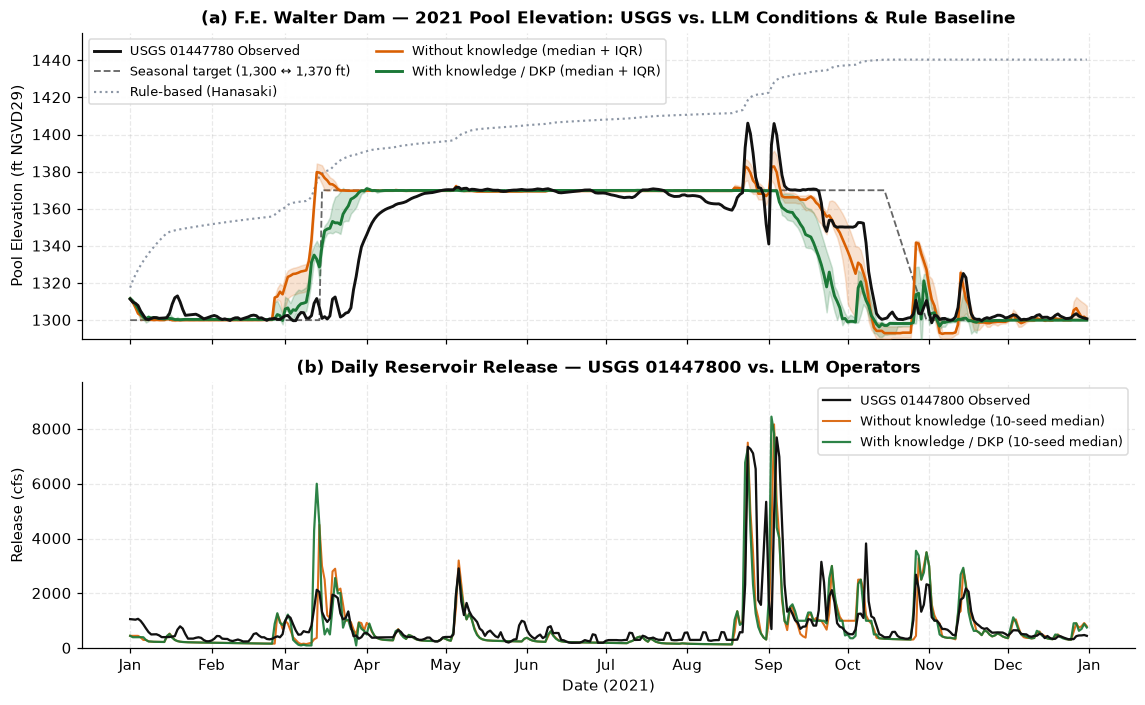

In [5]:
import matplotlib.dates as mdates
from datetime import date

dt_2021 = pd.to_datetime(obs_2021["date"])
target_2021 = np.array([formatter_mod._retrieval_target(d.date()) for d in dt_2021])

wo_lvl = np.vstack(sim_levels["without_knowledge"])
wi_lvl = np.vstack(sim_levels["with_knowledge"])
wo_rel = np.vstack(sim_releases["without_knowledge"])
wi_rel = np.vstack(sim_releases["with_knowledge"])

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10.5, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.15, 1.0]}
)

# Panel (a): Pool Elevation
ax1.plot(dt_2021, obs_2021["water_level_ft"], color="#111111", lw=1.9, label="USGS 01447780 Observed", zorder=5)
ax1.plot(dt_2021, target_2021, color="#666666", ls="--", lw=1.2, label="Seasonal target (1,300 ↔ 1,370 ft)", zorder=2)
ax1.plot(dt_2021, rule_lvl, color="#8c96a5", ls=":", lw=1.4, label="Rule-based (Hanasaki)", zorder=2)

ax1.fill_between(dt_2021, np.percentile(wo_lvl, 25, axis=0), np.percentile(wo_lvl, 75, axis=0),
                 color="#d95f02", alpha=0.18, zorder=3)
ax1.plot(dt_2021, np.median(wo_lvl, axis=0), color="#d95f02", lw=1.7,
         label="Without knowledge (median + IQR)", zorder=4)

ax1.fill_between(dt_2021, np.percentile(wi_lvl, 25, axis=0), np.percentile(wi_lvl, 75, axis=0),
                 color="#1b7837", alpha=0.20, zorder=3)
ax1.plot(dt_2021, np.median(wi_lvl, axis=0), color="#1b7837", lw=1.9,
         label="With knowledge / DKP (median + IQR)", zorder=4)

ax1.set_ylabel("Pool Elevation (ft NGVD29)")
ax1.set_title("(a) F.E. Walter Dam — 2021 Pool Elevation: USGS vs. LLM Conditions & Rule Baseline")
ax1.set_ylim(1290, 1455)
ax1.legend(loc="upper left", ncol=2, fontsize=8.4)

# Panel (b): Reservoir Release
ax2.plot(dt_2021, obs_2021["release_cfs"], color="#111111", lw=1.5, label="USGS 01447800 Observed", zorder=5)
ax2.plot(dt_2021, np.median(wo_rel, axis=0), color="#d95f02", lw=1.35, alpha=0.9,
         label="Without knowledge (10-seed median)", zorder=3)
ax2.plot(dt_2021, np.median(wi_rel, axis=0), color="#1b7837", lw=1.45, alpha=0.92,
         label="With knowledge / DKP (10-seed median)", zorder=4)

ax2.set_ylabel("Release (cfs)")
ax2.set_xlabel("Date (2021)")
ax2.set_title("(b) Daily Reservoir Release — USGS 01447800 vs. LLM Operators")
ax2.set_ylim(0, max(obs_2021["release_cfs"].max(), np.median(wi_rel, axis=0).max()) * 1.15)
ax2.xaxis.set_major_locator(mdates.MonthLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax2.legend(loc="upper right", fontsize=8.6)

fig.tight_layout()
plt.show()


## Key Takeaways & Next Step

- **Operational knowledge sharpens seasonal tracking & storm recovery:** Supplying structured WCM rules via `dkp.md` improves 2021 reservoir-level KGE/NSE and lowers RMSE while maintaining strong downstream Lehighton flow agreement.
- **Zero-cost prompt & schema verification:** `reservoir-experiment check` lets you audit prompt templates, SHA-256 source dependencies, and JSON response schemas before spending a single LLM token.
- **Next Module →** [`Module 03: Watershed Hydrology, 10-Year C&V & HydroCNHS Coupling`](../03_watershed_hydrology_and_cv/README.md) moves upstream into the rainfall-runoff engine (`GWLF` + `Lohmann`) on Taiwan's Xindian River basin.
